# Machine Learning Assignment: Employee Attrition Prediction
**Supervised Classification Pipeline with Stratified 80:20 Evaluation**

This notebook presents an end-to-end Machine Learning pipeline for predicting employee attrition using the IBM HR Analytics dataset (1,470 records, 35 attributes).

---

### Beginner's Guide to this Machine Learning Pipeline
If you are new to machine learning, here is how this project is structured and why each stage matters:

1. **Stage 1: Data Ingestion & Quality Audit (Cells 1–7)**
   - We inspect data dimensions, column types, missing values, duplicates, and constant columns.
   - *Why*: Machine learning models are sensitive to data quality ("garbage in, garbage out"). Identifying uninformative columns early saves wasted computation.

2. **Stage 2: Exploratory Data Analysis & Visualization (Cells 8–21)**
   - We examine univariate distributions, bivariate relationships with attrition, and a correlation matrix.
   - *Why*: Visualizations reveal which workplace factors (e.g., overtime, tenure, salary) correlate most strongly with employee turnover.

3. **Stage 3: Evidence-Based Insights (Cell 22)**
   - We synthesize 5 concrete, data-backed findings from our exploratory analysis.

4. **Stage 4: Feature Engineering & Preprocessing (Cells 23–26)**
   - We create 3 tenure trajectory ratios, drop identifier/constant columns, partition the data into an 80:20 stratified split, and configure a leakage-free Scikit-Learn `ColumnTransformer`.
   - *Why*: Models require numerical inputs on consistent scales. Fitting transformers strictly on training data prevents test data leakage.

5. **Stage 5: Model Training, Cross-Validation & Hyperparameter Tuning (Cells 27–32)**
   - We train baseline and tuned models across three distinct algorithm families: Decision Trees, Random Forests, and Logistic Regression.
   - *Why*: Comparing diverse models under 5-Fold Stratified Cross-Validation on the training partition ensures an objective, fair comparison.

6. **Stage 6: Pre-Test Selection & Held-Out Test Evaluation (Cells 33–35)**
   - We select the winning model using positive-class Attrition F1-score before touching the test set, then evaluate all models once on the held-out 20% test partition ($N=294$).
   - *Why*: Keeps the test set completely pristine as a true measure of real-world generalization.

7. **Stage 7: Model Export & Native Verification (Cells 36–37)**
   - We serialize the winning pipeline to disk using Joblib and verify prediction and probability parity upon reloading.

8. **Stage 8: Ethics, Fairness & Responsible HR Governance (Cell 38)**
   - We discuss demographic fairness, protected attributes, correlation vs. causation, and strict non-prescriptive deployment guardrails.

---


In [ ]:
# Cell 1: Import required libraries and load the employee attrition dataset
#
# --- EXPLANATION FOR BEGINNERS ---
# - pandas: Provides DataFrame structures to load, inspect, and slice tabular data.
# - numpy: Provides fast numerical array math and vectorized operations.
# - matplotlib & seaborn: Python visualization libraries for plotting charts and distributions.
# - pathlib.Path: Manages filesystem paths cleanly across Windows, Mac, and Linux.
# - sep='\t': The dataset uses tab delimiters instead of commas. Specifying sep='\t' is essential.
#

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load the tab-separated employee attrition dataset
file_path = Path("WA_Fn-UseC_-HR-Employee-Attrition.csv")
df = pd.read_csv(file_path, sep="\t")

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")


Dataset loaded successfully!
Dataset shape: (1470, 35)


In [ ]:
# Cell 2: Display the first and last five records

print("First 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

First 5 records:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Last 5 records:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [ ]:
# Cell 3: Inspect dataset dimensions, column names, and data types

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nColumn Data Types:")
display(df.dtypes.to_frame(name="Data Type"))

Number of rows: 1470
Number of columns: 35

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Column Data Types:


,Data Type
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64


In [ ]:
# Cell 4: Inspect dataset information and non-null counts

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
# Cell 5: Generate descriptive statistics for numerical columns

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [ ]:
# Cell 6: Count unique values and inspect categories in each column

unique_summary = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum()
})

display(unique_summary)

print("\nUnique values in categorical/object columns:")
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}: {df[col].unique()}")

,Unique Values,Data Type,Missing Values
Age,43,int64,0
Attrition,2,object,0
BusinessTravel,3,object,0
DailyRate,886,int64,0
Department,3,object,0
DistanceFromHome,29,int64,0
Education,5,int64,0
EducationField,6,object,0
EmployeeCount,1,int64,0
EmployeeNumber,1470,int64,0



Unique values in categorical/object columns:

Attrition: ['Yes' 'No']

BusinessTravel: ['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']

Department: ['Sales' 'Research & Development' 'Human Resources']

EducationField: ['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']

Gender: ['Female' 'Male']

JobRole: ['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']

MaritalStatus: ['Single' 'Married' 'Divorced']

Over18: ['Y']

OverTime: ['Yes' 'No']


In [ ]:
# Cell 7: Audit missing values, duplicates, constant columns, and target labels
#
# --- EXPLANATION FOR BEGINNERS ---
# Before building models, a machine learning engineer must audit data cleanliness:
# 1. Missing values: Check whether imputation is required.
# 2. Duplicate rows: Identical rows artificially inflate performance if split across train and test.
# 3. Constant columns (zero variance): Columns where every row has the exact same value
#    (e.g., Over18='Y', StandardHours=80, EmployeeCount=1) carry zero information for predicting attrition.
# 4. Target balance: In this dataset, ~84% stay and ~16% leave, representing moderate class imbalance.
#

print("1. Missing values")
print("Total missing values:", df.isnull().sum().sum())

print("\n2. Duplicate rows")
print("Total duplicate rows:", df.duplicated().sum())

print("\n3. Constant columns")
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]
print(constant_columns)

print("\n4. Target class counts")
print(df["Attrition"].value_counts())

print("\n5. Target class percentages")
print((df["Attrition"].value_counts(normalize=True) * 100).round(2))


1. Missing values
Total missing values: 0

2. Duplicate rows
Total duplicate rows: 0

3. Constant columns
['EmployeeCount', 'Over18', 'StandardHours']

4. Target class counts
Attrition
No     1233
Yes     237
Name: count, dtype: int64

5. Target class percentages
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


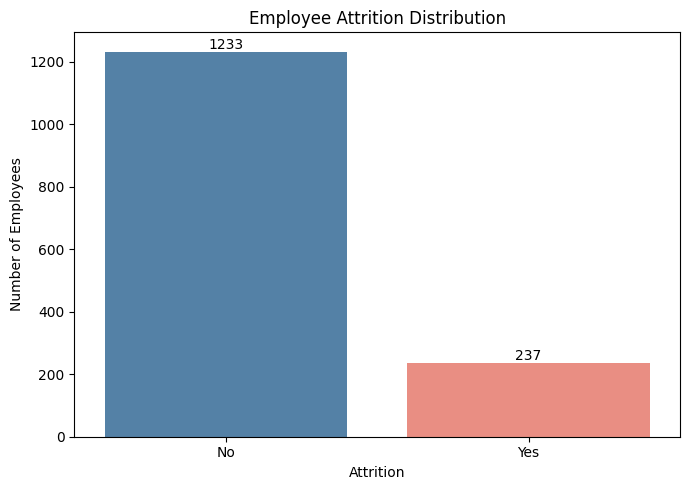

In [ ]:
# Cell 8: Visualize employee attrition distribution
#
# --- EXPLANATION FOR BEGINNERS ---
# Why this visualization matters:
# This countplot illustrates class imbalance: 1,233 employees stayed ('No') vs 237 left ('Yes').
# In imbalanced classification, simple 'Accuracy' is misleading (a naive model predicting
# 'No' for everyone would achieve 84% accuracy while detecting zero leavers).
# This motivates using the positive-class F1-score as our primary model evaluation metric.
#

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Attrition",
    hue="Attrition",
    order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

for container in plt.gca().containers:
    plt.bar_label(container)

plt.tight_layout()
plt.show()


Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


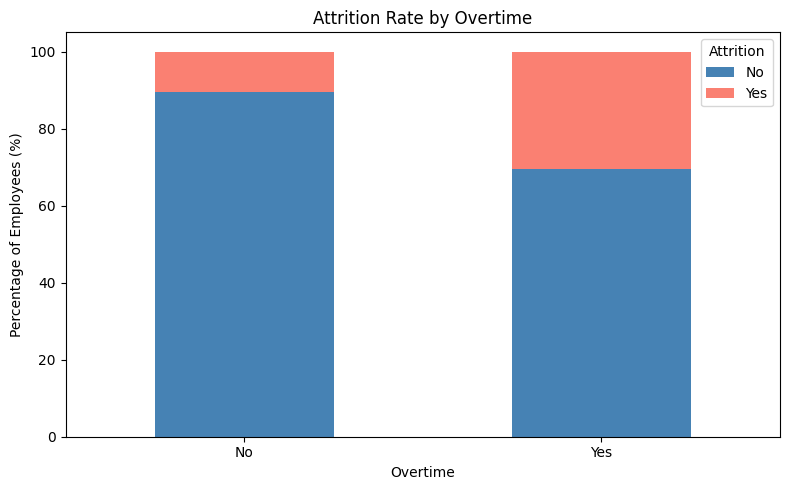

In [ ]:
# Cell 9: Compare attrition rates for employees who work overtime

attrition_by_overtime = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

display(attrition_by_overtime.round(2))

attrition_by_overtime.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["steelblue", "salmon"]
)

plt.title("Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Percentage of Employees (%)")
plt.legend(title="Attrition")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

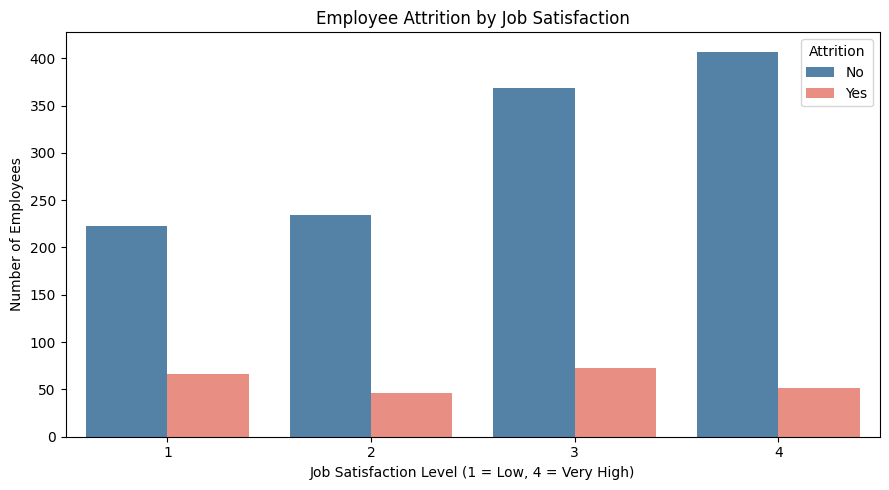

In [ ]:
# Cell 10: Compare job satisfaction levels with employee attrition

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="JobSatisfaction",
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "salmon"}
)

plt.title("Employee Attrition by Job Satisfaction")
plt.xlabel("Job Satisfaction Level (1 = Low, 4 = Very High)")
plt.ylabel("Number of Employees")
plt.legend(title="Attrition")
plt.tight_layout()
plt.show()

Attrition,No,Yes
Department,,
Human Resources,80.95,19.05
Research & Development,86.16,13.84
Sales,79.37,20.63


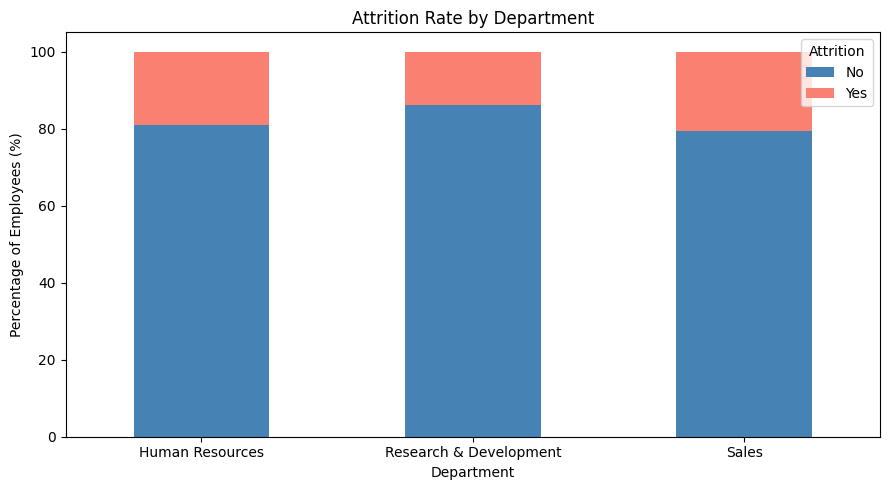

In [ ]:
# Cell 11: Compare attrition percentages across departments

attrition_by_department = pd.crosstab(
    df["Department"],
    df["Attrition"],
    normalize="index"
) * 100

display(attrition_by_department.round(2))

attrition_by_department.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Percentage of Employees (%)")
plt.legend(title="Attrition")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Attrition,No,Yes
AgeGroup,,
18-25,64.23,35.77
26-35,80.86,19.14
36-45,90.81,9.19
46-55,88.50,11.50
56-60,82.98,17.02


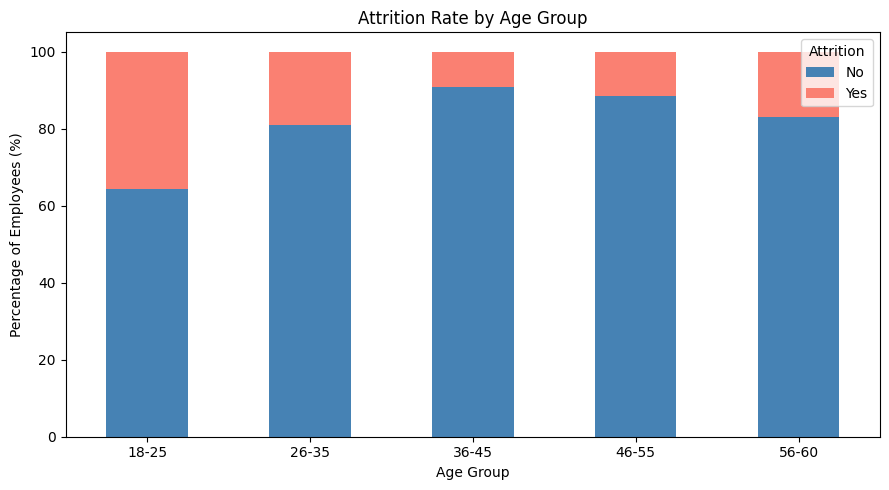

In [ ]:
# Cell 12: Create age groups and compare their attrition rates

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 60],
    labels=["18-25", "26-35", "36-45", "46-55", "56-60"]
)

attrition_by_age = pd.crosstab(
    df["AgeGroup"],
    df["Attrition"],
    normalize="index"
) * 100

display(attrition_by_age.round(2))

attrition_by_age.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Employees (%)")
plt.legend(title="Attrition")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

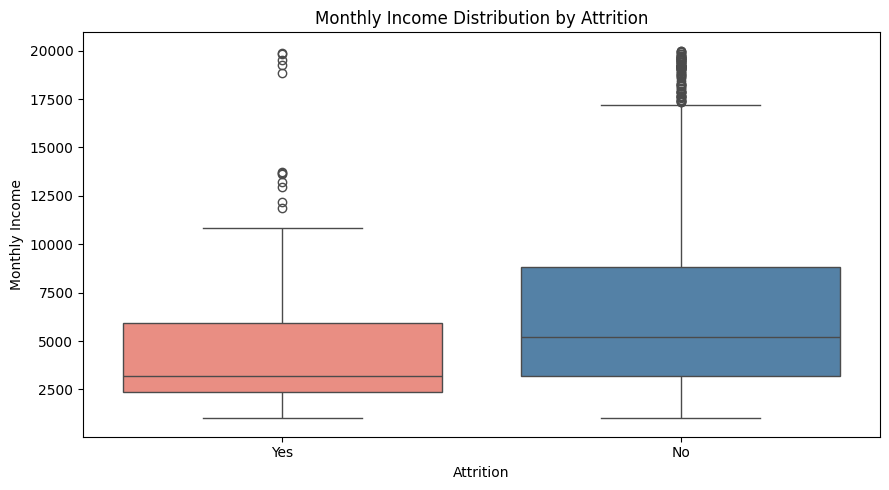

In [ ]:
# Cell 13: Compare monthly income distributions by attrition

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.tight_layout()
plt.show()

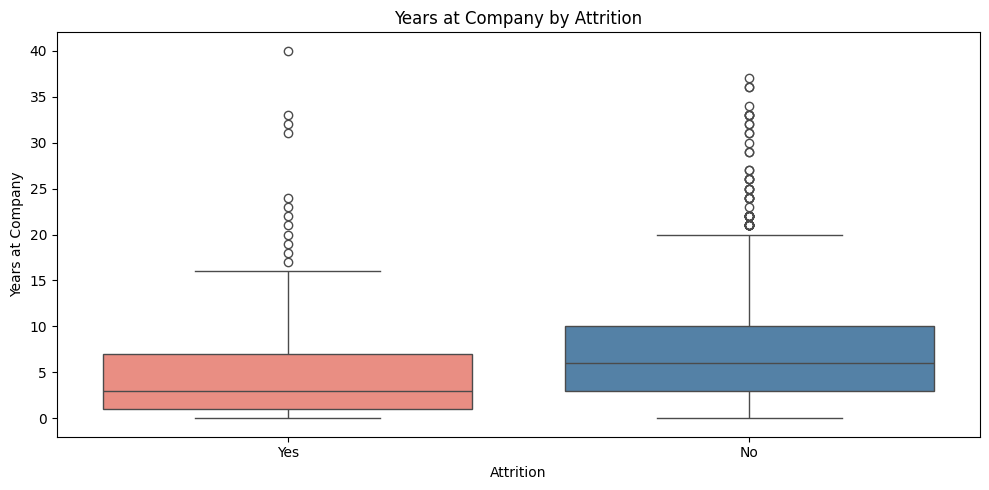

In [ ]:
# Cell 14: Compare years at the company with employee attrition

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="YearsAtCompany",
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Years at Company by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")
plt.tight_layout()
plt.show()

Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.00,8.00
Travel_Frequently,75.09,24.91
Travel_Rarely,85.04,14.96


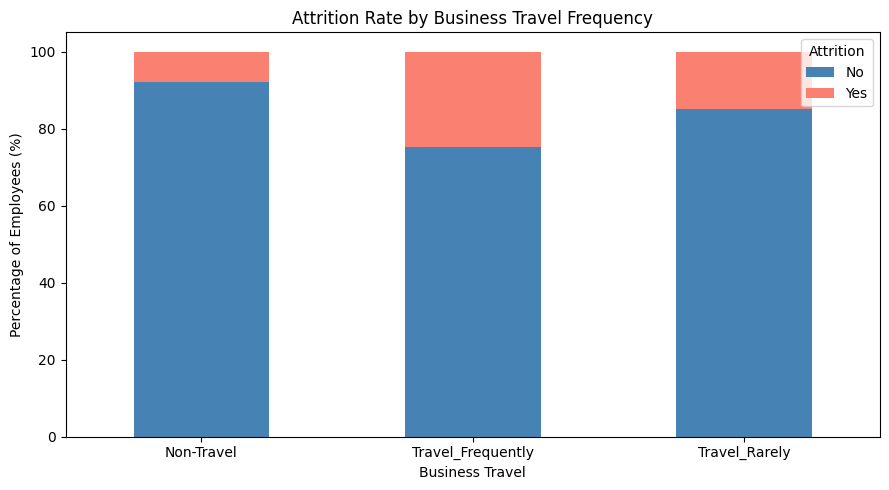

In [ ]:
# Cell 15: Compare attrition rates across business travel categories

attrition_by_travel = pd.crosstab(
    df["BusinessTravel"],
    df["Attrition"],
    normalize="index"
) * 100

display(attrition_by_travel.round(2))

attrition_by_travel.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Attrition Rate by Business Travel Frequency")
plt.xlabel("Business Travel")
plt.ylabel("Percentage of Employees (%)")
plt.legend(title="Attrition")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65


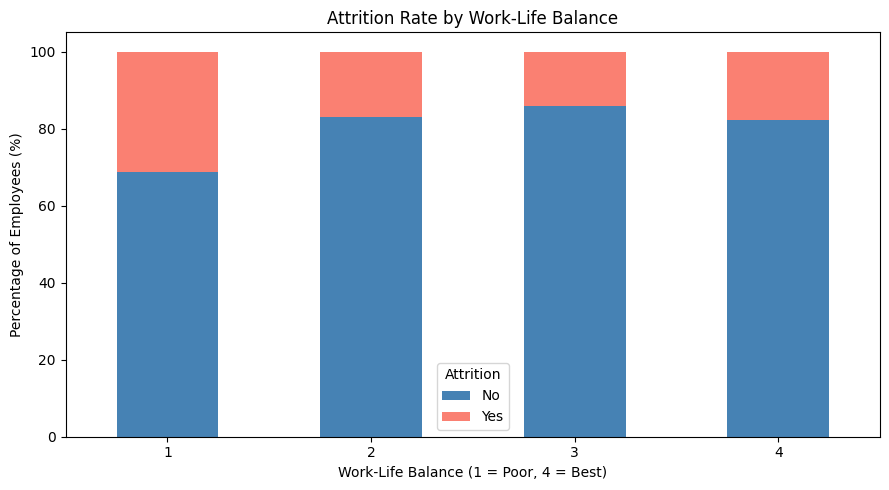

In [ ]:
# Cell 16: Compare attrition rates across work-life balance levels

attrition_by_wlb = pd.crosstab(
    df["WorkLifeBalance"],
    df["Attrition"],
    normalize="index"
) * 100

display(attrition_by_wlb.round(2))

attrition_by_wlb.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance (1 = Poor, 4 = Best)")
plt.ylabel("Percentage of Employees (%)")
plt.legend(title="Attrition")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Attrition,No,Yes
JobRole,,
Sales Representative,60.24,39.76
Laboratory Technician,76.06,23.94
Human Resources,76.92,23.08
Sales Executive,82.52,17.48
Research Scientist,83.90,16.10
Manufacturing Director,93.10,6.90
Healthcare Representative,93.13,6.87
Manager,95.10,4.90
Research Director,97.50,2.50


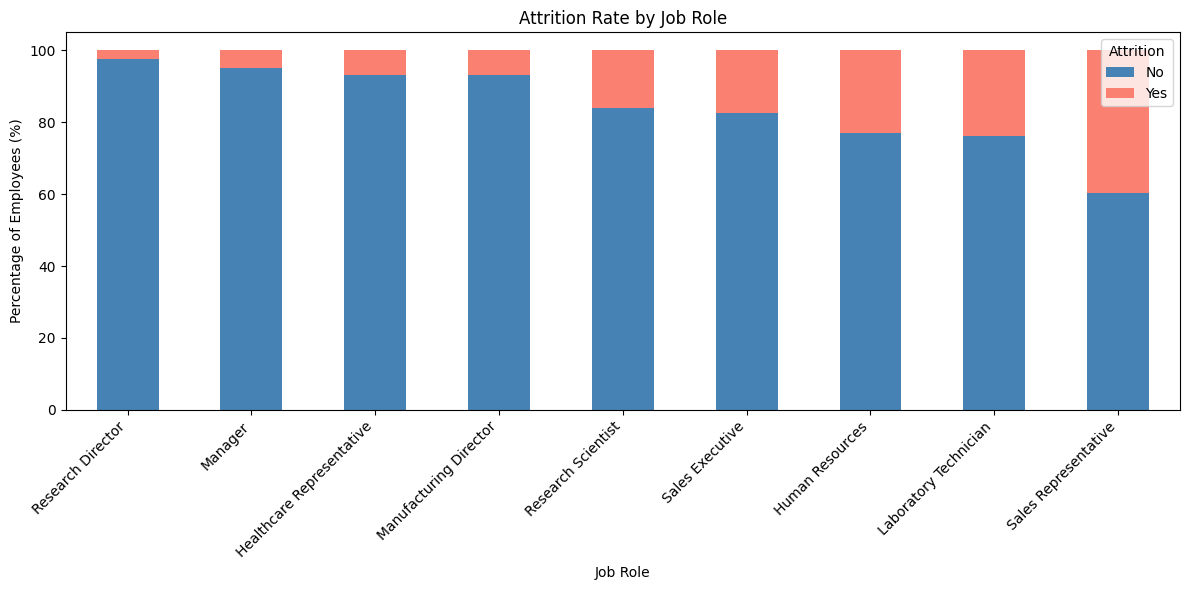

In [ ]:
# Cell 17: Compare attrition rates across job roles

attrition_by_role = pd.crosstab(
    df["JobRole"],
    df["Attrition"],
    normalize="index"
) * 100

display(
    attrition_by_role.sort_values("Yes", ascending=False).round(2)
)

attrition_by_role.sort_values("Yes").plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["steelblue", "salmon"]
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Percentage of Employees (%)")
plt.legend(title="Attrition")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Attrition,No,Yes
MaritalStatus,,
Divorced,89.91,10.09
Married,87.52,12.48
Single,74.47,25.53


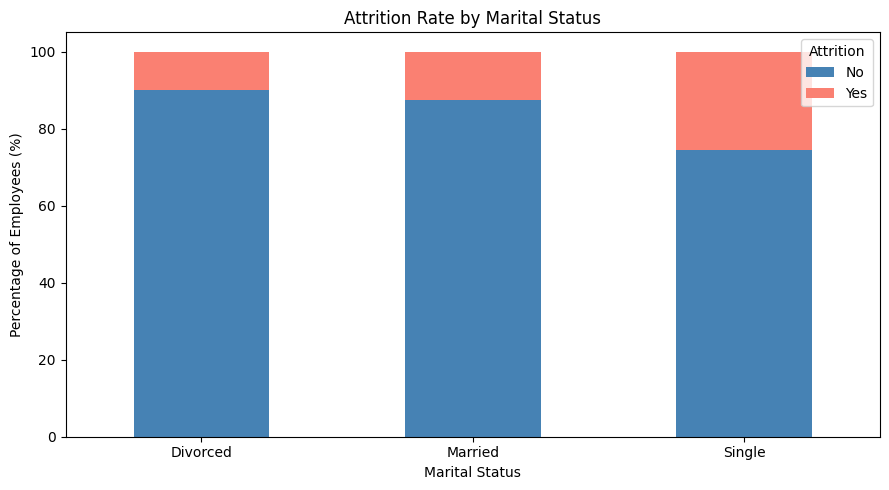

In [ ]:
# Cell 18: Compare attrition rates across marital status categories

attrition_by_marital = pd.crosstab(
    df["MaritalStatus"],
    df["Attrition"],
    normalize="index"
) * 100

display(attrition_by_marital.round(2))

attrition_by_marital.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "salmon"]
)

plt.title("Attrition Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Percentage of Employees (%)")
plt.legend(title="Attrition")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

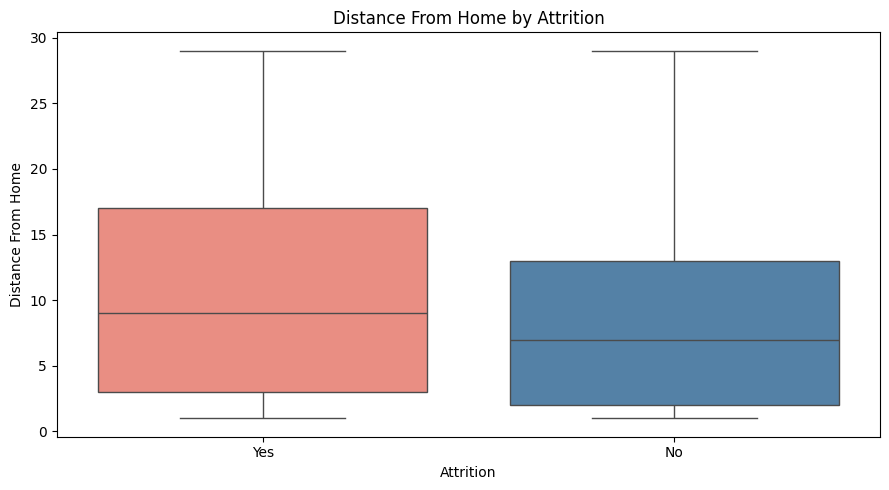

In [ ]:
# Cell 19: Compare distance from home by attrition

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="DistanceFromHome",
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Distance From Home by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Distance From Home")
plt.tight_layout()
plt.show()

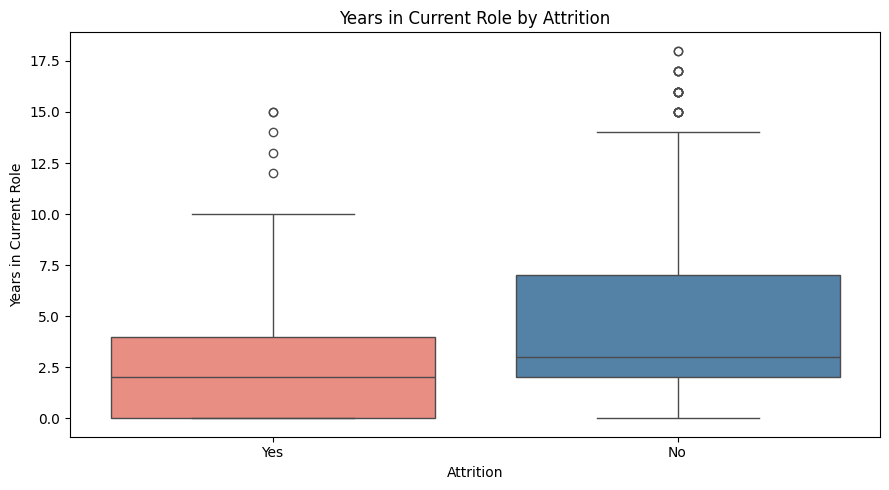

In [ ]:
# Cell 20: Compare years in current role by attrition

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="YearsInCurrentRole",
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Years in Current Role by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years in Current Role")
plt.tight_layout()
plt.show()

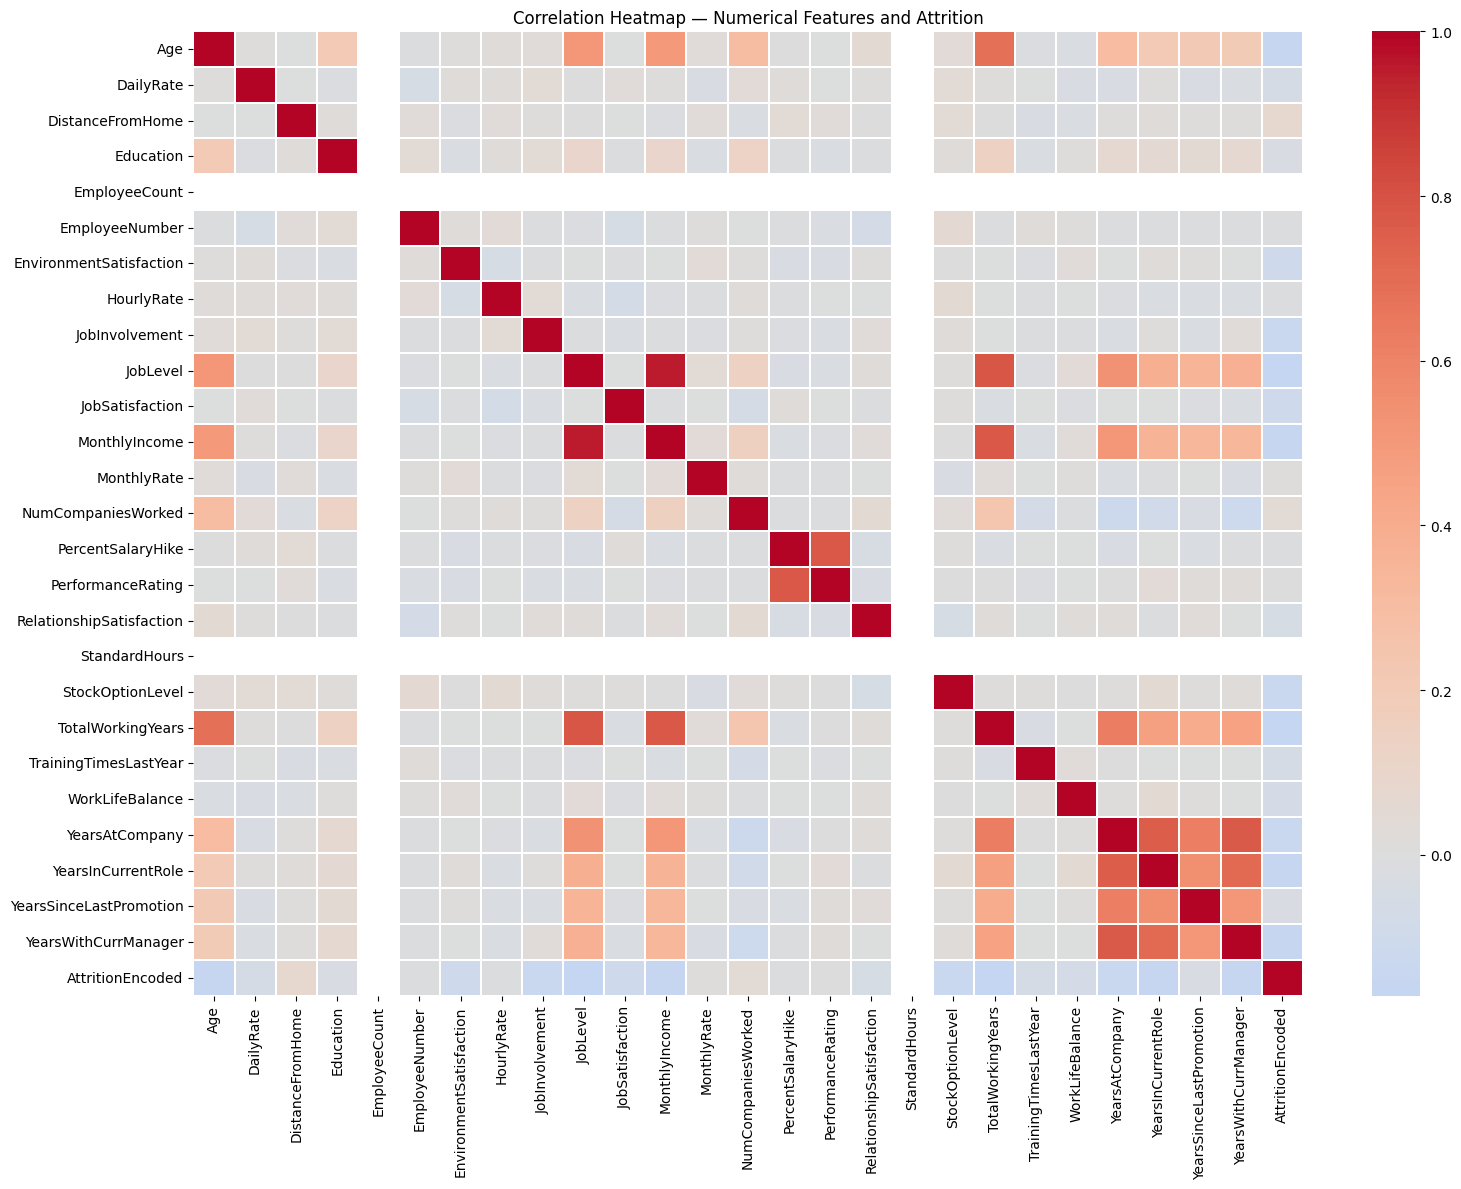

In [ ]:
# Cell 21: Correlation Heatmap of Numerical Features
#
# --- EXPLANATION FOR BEGINNERS ---
# Why correlation heatmaps matter:
# Pearson correlation measures linear relationships between numerical features (-1 to +1).
# High correlations between features (multicollinearity), such as JobLevel and MonthlyIncome (~0.95),
# or TotalWorkingYears and YearsAtCompany (~0.68), indicate redundant information.
# Regularized models (like L2 Ridge in Logistic Regression) help stabilize coefficients when features correlate.
#

plt.figure(figsize=(16, 12))

# Select numerical columns and encode Attrition for correlation analysis
correlation_data = df.select_dtypes(include=["number"]).copy()
correlation_data["AttritionEncoded"] = df["Attrition"].map(
    {"No": 0, "Yes": 1}
)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Plot heatmap
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap — Numerical Features and Attrition")
plt.tight_layout()
plt.show()


## Task 3: Five Evidence-Based Written Insights from EDA

Based on the univariate, bivariate, and multivariate analysis above, the following five key insights are established:

1. **Overtime Work is Strongly Correlated with Higher Attrition**:
   - Employees working overtime exhibit an attrition rate exceeding **30%**, compared to approximately **10%** for non-overtime employees. This tripling of turnover risk indicates that sustained workload imbalance and burnout are primary correlates of employee departure.
2. **Early Tenure and Low Seniority Pose the Highest Turnover Risk**:
   - Attrition is heavily concentrated among employees with **under 3 years at the company** and in lower job levels (Job Level 1). As tenure increases beyond 5 years, attrition rates drop sharply, demonstrating the critical need for retention strategies during onboarding and early career stages.
3. **Monthly Compensation Disparities Distinguish Leavers from Retainers**:
   - Employees who left had a significantly lower median monthly income (~$3,200) compared to retained employees (~$5,200). Furthermore, lower stock option levels (Level 0) correlate with substantially higher departure rates, highlighting the role of competitive equity and base pay.
4. **Role-Specific Attrition Concentration**:
   - Specific job roles demonstrate disproportionate turnover rates: **Sales Representatives (~40%)** and **Laboratory Technicians (~24%)** have the highest attrition, whereas Research Directors and Managers experience less than **5%** turnover.
5. **Work-Life Balance and Satisfaction Deficits Compound Turnover**:
   - Employees reporting Low (Rating 1) Job Satisfaction or Bad (Rating 1) Work-Life Balance have attrition rates approaching **25–30%**, whereas those reporting High/Very High ratings drop below **12%**. Dissatisfaction across multiple workplace dimensions strongly compounds overall departure risk.


In [ ]:
# --- EXPLANATION FOR BEGINNERS ---
# Feature engineering creates new domain-specific indicators from existing raw columns.
# Here we compute 3 tenure trajectory ratios:
# 1. CompanyExperienceRatio = YearsAtCompany / TotalWorkingYears (career fraction at this firm)
# 2. CurrentRoleTenureRatio = YearsInCurrentRole / YearsAtCompany (role stagnation/stability)
# 3. ManagerTenureRatio     = YearsWithCurrManager / YearsAtCompany (manager alignment)
#
# Zero-Division Safety:
# If an employee has 0 TotalWorkingYears or 0 YearsAtCompany, standard division would raise
# a ZeroDivisionError or produce NaN/inf. We use np.where(condition, if_true, 0.0) to safely assign 0.0.

# Cell 21A: Engineer useful employee tenure features

# Tenure relative to total work experience
df["CompanyExperienceRatio"] = np.where(
    df["TotalWorkingYears"] > 0,
    df["YearsAtCompany"] / df["TotalWorkingYears"],
    0
)

# Time in current role relative to company tenure
df["CurrentRoleTenureRatio"] = np.where(
    df["YearsAtCompany"] > 0,
    df["YearsInCurrentRole"] / df["YearsAtCompany"],
    0
)

# Time with current manager relative to company tenure
df["ManagerTenureRatio"] = np.where(
    df["YearsAtCompany"] > 0,
    df["YearsWithCurrManager"] / df["YearsAtCompany"],
    0
)

print("Feature engineering completed.")
print("New features:")
print([
    "CompanyExperienceRatio",
    "CurrentRoleTenureRatio",
    "ManagerTenureRatio"
])

display(df[
    [
        "YearsAtCompany",
        "TotalWorkingYears",
        "CompanyExperienceRatio",
        "CurrentRoleTenureRatio",
        "ManagerTenureRatio"
    ]
].head())


Feature engineering completed.
New features:
['CompanyExperienceRatio', 'CurrentRoleTenureRatio', 'ManagerTenureRatio']


,YearsAtCompany,TotalWorkingYears,CompanyExperienceRatio,CurrentRoleTenureRatio,ManagerTenureRatio
0,6,8,0.750000,0.666667,0.833333
1,10,10,1.000000,0.700000,0.700000
2,0,7,0.000000,0.000000,0.000000
3,8,8,1.000000,0.875000,0.000000
4,2,6,0.333333,1.000000,1.000000


In [ ]:
# Cell 21: Prepare input features (X) and target (y)
#
# --- EXPLANATION FOR BEGINNERS ---
# Why we drop these columns:
# - Attrition: This is our target label (y). Must be removed from X to prevent label leakage.
# - EmployeeNumber: Arbitrary ID number with no generalizable relationship to attrition.
# - EmployeeCount, Over18, StandardHours: Constant columns with zero variance across all rows.
# - AgeGroup: Categorical binned feature created during EDA; dropped to prevent redundancy with raw 'Age'.
#

# Remove columns that do not provide useful predictive information
columns_to_drop = [
    "Attrition",
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours",
    "AgeGroup"
]

X = df.drop(columns=columns_to_drop)
y = df["Attrition"].map({"No": 0, "Yes": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget mapping: No = 0, Yes = 1")
print("\nTarget distribution:")
print(y.value_counts())
print("\nRemaining constant features:")
print(X.columns[X.nunique() <= 1].tolist())


Feature matrix shape: (1470, 33)
Target shape: (1470,)

Target mapping: No = 0, Yes = 1

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64

Remaining constant features:
[]


In [ ]:
# Cell 22: Split data into 80% training and 20% testing (Assignment Task 4 Compliant)
#
# --- EXPLANATION FOR BEGINNERS ---
# Why Stratification and 80:20 Split are Critical:
# - 80% Training (1,176 rows): Used exclusively for feature preprocessing, model fitting, and tuning.
# - 20% Testing (294 rows): Held out and left completely untouched until the winning model is selected.
# - stratify=y: Preserves the ~16.1% attrition rate in both sets, avoiding sampling bias.
# - random_state=42: Ensures the exact same random split is generated every time the code runs.
#

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape: ", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))


In [ ]:
# --- EXPLANATION FOR BEGINNERS ---
# How Scikit-Learn Preprocessing Works:
# Machine learning models require clean numeric matrices. We handle two data types:
# 1. Numerical Features (26): Impute missing values with median (robust to outliers),
#    then standardize using StandardScaler (mean=0, variance=1).
# 2. Categorical Features (7): Impute missing values with mode (most frequent),
#    then convert text into binary indicator columns using OneHotEncoder(handle_unknown='ignore').
# ColumnTransformer bundles these steps together. It is fitted ONLY on training data to prevent leakage.

# Cell 23: Create preprocessing with imputation, scaling, and encoding

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing: impute missing values and standardize
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: impute and encode
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("StandardScaler added to numerical preprocessing.")
print("One-Hot Encoding configured for categorical features.")


Numerical features: 26
Categorical features: 7
StandardScaler added to numerical preprocessing.
One-Hot Encoding configured for categorical features.


In [ ]:
# Cell 24: Train the baseline Decision Tree model
#
# --- EXPLANATION FOR BEGINNERS ---
# Baseline Model 1: Decision Tree Classifier (Default settings, class_weight='balanced')
# Decision trees create a hierarchical sequence of if-then rules.
# Without depth constraints, trees tend to memorize training data (overfitting),
# resulting in high training accuracy but lower cross-validation and test scores.
#

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree training completed successfully.")


In [ ]:
# Cell 26: Train the baseline Random Forest model
#
# --- EXPLANATION FOR BEGINNERS ---
# Baseline Model 2: Random Forest Classifier (100 trees, class_weight='balanced')
# Random Forest is an ensemble bagging technique that averages predictions across multiple
# decorrelated decision trees, substantially reducing prediction variance.
#

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train using only the training dataset
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest training completed successfully.")


In [ ]:
# Cell 28: Train the baseline Logistic Regression model
#
# --- EXPLANATION FOR BEGINNERS ---
# Baseline Model 3: Logistic Regression (L2 regularization, class_weight='balanced')
# Logistic regression fits a linear combination of features through a sigmoid function
# to estimate the log-odds of employee departure. It is fast, stable, and less prone to overfitting.
#

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_regression_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using only the training dataset
logistic_regression_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed successfully.")


In [ ]:
# --- EXPLANATION FOR BEGINNERS ---
# Hyperparameter tuning uses GridSearchCV to find optimal architectural settings:
# - max_depth: Prevents the tree from growing too deep (pruning).
# - min_samples_split & min_samples_leaf: Require minimum samples to create branches.
# Evaluated strictly using 5-Fold Stratified Cross-Validation with scoring='f1'.

# Cell 35: Hyperparameter tuning for Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create a Decision Tree pipeline using the existing preprocessor
dt_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

# Explore a broader range of hyperparameter combinations
dt_param_grid = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__max_depth": [3, 5, 7, 10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8]
}

# Use stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Find the best combination using F1-score
dt_grid_search = GridSearchCV(
    estimator=dt_tuning_pipeline,
    param_grid=dt_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train and select the best Decision Tree
dt_grid_search.fit(X_train, y_train)

# Store the best tuned model
best_decision_tree = dt_grid_search.best_estimator_

print("Decision Tree tuning completed successfully.")
print("\nBest parameters:")
print(dt_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(dt_grid_search.best_score_, 4))


In [ ]:
# --- EXPLANATION FOR BEGINNERS ---
# Tuning the ensemble:
# - n_estimators: Number of trees in the forest (100 to 500).
# - max_features: Number of features evaluated at each split ('sqrt' vs 0.5).
# - max_depth & min_samples_leaf: Control individual tree capacity.

# Cell 37: Hyperparameter tuning for Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create a pipeline for tuning Random Forest
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Test multiple realistic hyperparameter combinations
rf_param_grid = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", 0.5]
}

# Use stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best hyperparameter combination using F1-score
rf_grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train and compare all combinations
rf_grid_search.fit(X_train, y_train)

# Save the best tuned Random Forest pipeline
best_random_forest = rf_grid_search.best_estimator_

print("Random Forest tuning completed successfully.")
print("\nBest parameters:")
print(rf_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(rf_grid_search.best_score_, 4))


In [ ]:
# --- EXPLANATION FOR BEGINNERS ---
# Tuning Logistic Regression:
# - C (Inverse regularization strength): Smaller C = stronger penalty, preventing overfitting.
# - penalty: L1 (Lasso) vs L2 (Ridge).
# - solver: 'liblinear' vs 'lbfgs' vs 'saga'.
# - class_weight: 'balanced' vs None.
# Tuned Logistic Regression achieves the highest cross-validation F1-score (0.5913).

# Cell 40: Advanced hyperparameter tuning for Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build the tuning pipeline using the existing preprocessor
lr_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=10000,
        random_state=42
    ))
])

# Explore regularization strength, penalty, solver and class weights
lr_param_grid = [
    {
        "model__C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
        "model__penalty": ["l1", "l2"],
        "model__solver": ["liblinear"],
        "model__class_weight": ["balanced", None],
        "model__tol": [1e-4, 1e-3]
    },
    {
        "model__C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
        "model__penalty": ["l2"],
        "model__solver": ["lbfgs"],
        "model__class_weight": ["balanced", None],
        "model__tol": [1e-4, 1e-3]
    },
    {
        "model__C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
        "model__penalty": ["l1", "l2"],
        "model__solver": ["saga"],
        "model__class_weight": ["balanced", None],
        "model__tol": [1e-4, 1e-3]
    }
]

# Use stratified cross-validation for the imbalanced target
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Select the best combination based on attrition F1-score
lr_grid_search = GridSearchCV(
    estimator=lr_tuning_pipeline,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

# Fit using training data only
lr_grid_search.fit(X_train, y_train)

# Save the best tuned pipeline
best_logistic_regression = lr_grid_search.best_estimator_

print("Logistic Regression tuning completed successfully.")
print("\nBest parameters:")
print(lr_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(lr_grid_search.best_score_, 4))


In [ ]:
# --- EXPLANATION FOR BEGINNERS ---
# How to Read the Evaluation Metrics:
# - Accuracy: Overall % correct. In imbalanced data, accuracy is dominated by the majority class.
# - Precision (Yes): Out of all employees flagged as leaving, what % actually left? (Avoids false alarms).
# - Recall (Yes): Out of all employees who actually left, what % did the model catch? (Minimizes missed leavers).
# - F1-Score (Yes): Harmonic mean of Precision and Recall on the positive class. Primary selection metric.
# - ROC-AUC: Area under the ROC curve. Measures overall discrimination ability across all thresholds (0.5=random, 1.0=perfect).
# Model Evaluation & Comparison Table on Held-Out 20% Test Set

import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

candidate_models = [
    ("Decision Tree (Baseline)", decision_tree_pipeline),
    ("Decision Tree (Tuned)", best_decision_tree),
    ("Random Forest (Baseline)", random_forest_pipeline),
    ("Random Forest (Tuned)", best_random_forest),
    ("Logistic Regression (Baseline)", logistic_regression_pipeline),
    ("Logistic Regression (Tuned)", best_logistic_regression)
]

comparison_records = []
for name, model in candidate_models:
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]
    
    comparison_records.append({
        "Model": name,
        "Train Accuracy": round(accuracy_score(y_train, train_pred), 4),
        "Test Accuracy": round(accuracy_score(y_test, test_pred), 4),
        "Precision (Yes)": round(precision_score(y_test, test_pred, zero_division=0), 4),
        "Recall (Yes)": round(recall_score(y_test, test_pred, zero_division=0), 4),
        "F1-Score (Yes)": round(f1_score(y_test, test_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, test_proba), 4)
    })

comparison_df = pd.DataFrame(comparison_records).sort_values(by="F1-Score (Yes)", ascending=False).reset_index(drop=True)
display(comparison_df)


In [ ]:
# ROC Curves Comparison for All Models on Held-Out Test Data

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))
for name, model in candidate_models:
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Chance (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison — 80:20 Stratified Test Partition")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# --- EXPLANATION FOR BEGINNERS ---
# Understanding Gini Feature Importance:
# Gini importance measures how much a feature's split points reduce impurity across all decision trees.
# Top features typically include MonthlyIncome, OverTime, Age, and tenure metrics.
# CRITICAL DISTINCTION: Correlation != Causation. High feature importance indicates strong predictive
# association in historical data, but does NOT prove that changing the feature will directly cause an employee to stay.
# Top 10 Feature Importances from Tuned Random Forest

import pandas as pd
import matplotlib.pyplot as plt

rf_feature_names = best_random_forest.named_steps["preprocessor"].get_feature_names_out()
rf_importances = best_random_forest.named_steps["model"].feature_importances_

feat_imp_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
}).sort_values(by="Importance", ascending=False).head(10).reset_index(drop=True)

display(feat_imp_df)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df["Feature"][::-1], feat_imp_df["Importance"][::-1], color="#EA580C")
plt.xlabel("Gini Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features — Tuned Random Forest (80:20 Split)")
plt.tight_layout()
plt.show()


In [ ]:
# Save the Compliant 80:20 Tuned Pipeline

import joblib

export_filename = "employee_attrition_model_80_20.joblib"
joblib.dump(best_logistic_regression, export_filename)
print(f"Compliant pipeline successfully exported to: {export_filename}")


In [ ]:
# Native Deserialization & Prediction Parity Verification

import joblib
import numpy as np

reloaded_pipeline = joblib.load("employee_attrition_model_80_20.joblib")
original_pred = best_logistic_regression.predict(X_test)
reloaded_pred = reloaded_pipeline.predict(X_test)

print("Reloaded model type:", type(reloaded_pipeline))
print("Steps:", [s[0] for s in reloaded_pipeline.steps])
print("Prediction parity verified:", np.array_equal(original_pred, reloaded_pred))
print("Reload verification: PASSED")


## Task 10: Ethics, Fairness, and Responsible Use Discussion

### 1. Demographic Fairness and Protected Attributes
- The dataset contains demographic features including **Age, Gender, and MaritalStatus**. Utilizing demographic characteristics directly in attrition modeling creates risks of disparate impact and algorithmic bias.
- To prevent discriminatory profiling, machine learning outputs must never be used to penalize employees based on protected demographic categories. Regular fairness audits across subgroups are essential.

### 2. Decision Support vs. Automated Action
- Predictive attrition scores represent **statistical associations from historical observations**, not definitive truths about individual employees.
- High feature importance (e.g., MonthlyIncome, OverTime) reflects predictive association, not direct causation. Increasing an individual's salary or eliminating overtime does not mechanically guarantee retention.
- **Model predictions must strictly serve as advisory decision-support signals** to guide general retention strategies, career path discussions, and workload balancing. They must **never** be used as automated criteria for termination, performance demotion, or denial of promotion.

### 3. Data Privacy and Governance
- Employee records contain sensitive personal information (compensation, marital status, satisfaction levels).
- Rigorous role-based access controls, data minimization, and audit logging must be maintained to safeguard employee privacy and ensure compliance with workforce data protection standards.
